# JPDA (Joint Probabilistic Data Association) Test

This notebook uses the implemented classes to create a JPDA tracker that
is tested with data from Rosbags.

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime
from collections import defaultdict

# third-party imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display
import tqdm

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.sensor_sim as ss
import multi_target_tracking as mtt

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

In [3]:
script_name = "04_JPDA"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)
# Log to file and console
logger.info("Notebook started - Testing Single Target Tracker (STT)")

INFO: Notebook started - Testing Single Target Tracker (STT)


## Dataset with two zebras

### Configuration

In [4]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/2_zebras_3_drones_gps_drift.bag')

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

#################### Topics and message counts: ####################
Topic: /gazebo/model_states
    Message type: TopicInfo(msgtype='gazebo_msgs/msg/ModelStates', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data='# broadcast all model states in world frame\nstring[] name                 # model names\ngeometry_msgs/Pose[] pose     # desired pose in world frame\ngeometry_msgs/Twist[] twist   # desired twist in world frame\n\n================================================================================\nMSG: geometry_msgs/Pose\n# A representation of pose in free space, composed of position and orientation. \nPoint position\nQuaternion orientation\n\n================================================================================\nMSG: geometry_msgs/Point\n# This contains the position of a point in free space\nfloat64 x\nfloat64 y\nfloat64 z\n\n================================================================================\nMSG: geometry_msgs/Quaternion\n# This 

### Data Extraction
Extract projection data (array and simple list) and ground truth

In [5]:
## DATA EXTRACTION
# Define topics to analyze
topics = [
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/target_tracker/MTT/GT/target2",
    "/machine_1/object_detections/projected_to_world",
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target2' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


Extract detection array messages

In [6]:
projected_array = rbu.import_detections_array_data(bag_reader, "/machine_1/object_detections/projected_to_world_array")
# Convert to DataFrame
time = []
meas = []
for timestamp, measurements, drone_id in projected_array:
    for measurement in measurements:
        time.append(timestamp)
        meas.append(measurement)
time = np.array(time)
meas = np.array(meas)
# Create DataFrame
projected_array_df = dfu.measurements_to_dataframe(meas, time)


INFO: Importing detections array data from topics: /machine_1/object_detections/projected_to_world_array


#### Analyze the projected detections

INFO: Average detections per frame: 1.50
INFO: Maximum detections in a frame: 4
INFO: Minimum detections in a frame: 1


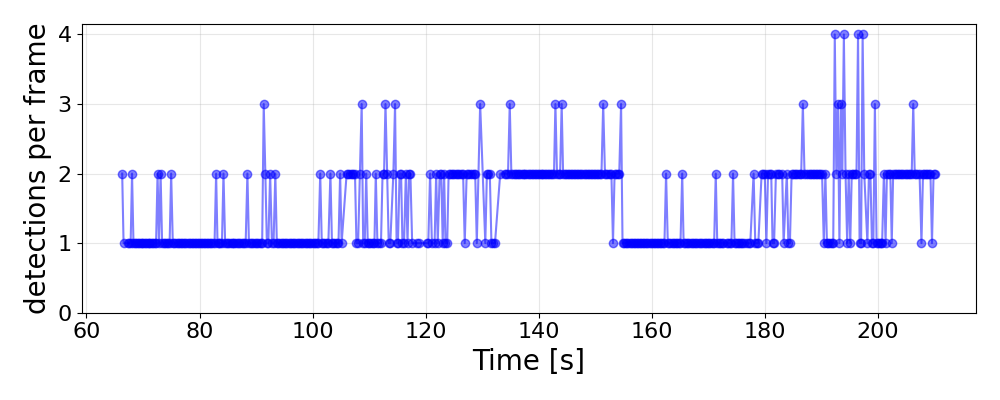

In [7]:
## Analyze the number of detections per frame
# get number of detections per frame
num_detections = [len(meas) for _, meas, _ in projected_array]
timestamps = [t for t, _, _ in projected_array]

# Calculate some statistics
avg_detections = np.mean(num_detections)
max_detections = np.max(num_detections)
min_detections = np.min(num_detections)
logger.info(f"Average detections per frame: {avg_detections:.2f}")
logger.info(f"Maximum detections in a frame: {max_detections}")
logger.info(f"Minimum detections in a frame: {min_detections}")

# Plot the number of detections per frame
plt.figure(figsize=(10, 4))
plt.plot(timestamps, num_detections, marker='o', linestyle='-', color='b', alpha=0.5)
# plt.title("Number of Detections per Frame", fontsize=24)
plt.xlabel("Time [s]", fontsize=20)
plt.ylabel("detections per frame", fontsize=20)

# Set integer ticks on y-axis
max_y = max(num_detections) + 1
y_ticks = np.arange(0, max_y, 1, dtype=int)
plt.yticks(y_ticks)

# Add a horizontal line for the average
# plt.axhline(y=avg_detections, color='r', linestyle='--', label=f'Avg: {avg_detections:.2f}')

# Add grid and legend
plt.grid(True, alpha=0.3)
plt.tight_layout()

# custom axis limits
# plt.xlim((60, 180))
# plt.ylim((4, 22))

In [8]:
# plt.savefig(os.path.join(PLOTS_DIR, "projected_meas.svg"), dpi=600, bbox_inches='tight')

### Tracking using projected detections

#### Tracker using projected measurements

In [9]:
## TEST 1: JPDA Tracker using projected detections
gater = mtt.MahalanobisGater()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
)

logger.info("Starting tracking using position detections")
# Evaluate the tracker using the grouped detections
for detection in tqdm.tqdm(projected_array, total=len(projected_array), desc="Proj Position Tracking"):
    tracker.evaluate(detection)
proj_results = tracker.tracks
print(f"Number of tracks: {len(proj_results)}")

INFO: Starting tracking using position detections


Proj Position Tracking: 100%|██████████| 492/492 [00:00<00:00, 941.45it/s] 

Number of tracks: 4


In [10]:
## Extract confirmed tracks
confirmed_proj_tracks = [track for track in proj_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_proj_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_proj_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in confirmed_proj_tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
proj_results_dfs = [dfu.track_to_dataframe(track) for track in confirmed_proj_tracks]

Number of confirmed tracks: 4
Number of active tracks in the end: 4


#### Plots

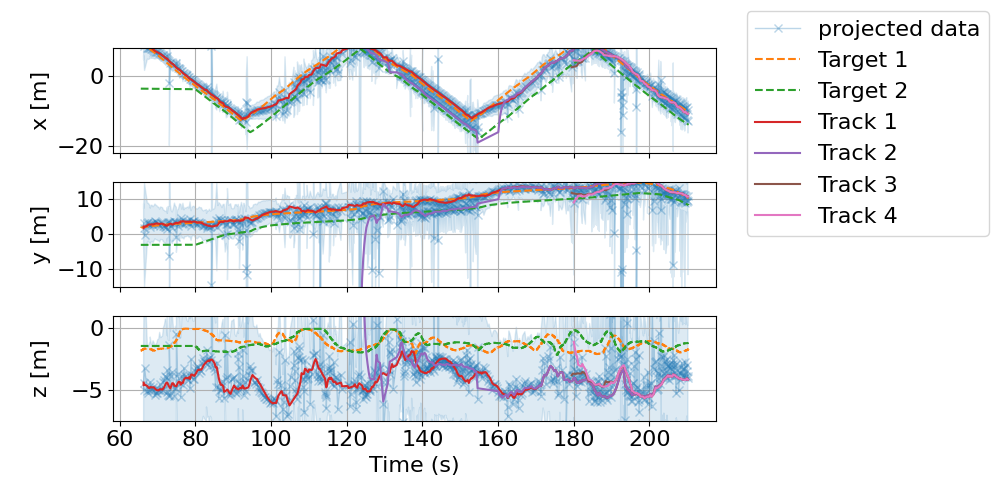

In [11]:
## JPDA with projected detections
fig_proj_tracks = pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], label="projected data", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True)

for i, (topic, data) in enumerate(topic_data.items()):
    if "GT" in topic:
        pu.plot_xyz_over_time(data, fig=fig_proj_tracks, label=f"Target {i+1}", linewidth=1.5, linestyle='--')

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(proj_results_dfs):
    pu.plot_xyz_over_time(track_df, fig=fig_proj_tracks, label=f"Track {i+1}", linewidth=1.5)
    # pu.plot_xyz_over_time(track_df, fig=fig_proj_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i])

handles, labels = fig_proj_tracks.axes[0].get_legend_handles_labels()
# fig_proj_tracks.legend(handles, labels, loc='upper right')
fig_proj_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 1.0))
fig_proj_tracks.suptitle("")
fig_proj_tracks.set_size_inches(10, 5)
fig_proj_tracks.tight_layout(rect=[0, 0, 0.74, 1.0])
fig_proj_tracks.align_ylabels()

# custom y-axis limits
fig_proj_tracks.axes[0].set_ylim((-22, 8))
fig_proj_tracks.axes[1].set_ylim((-15, 15))
fig_proj_tracks.axes[2].set_ylim((-7.5, 1))

# custom x-axis limits
# for ax in fig_proj_tracks.axes:
    # ax.set_xlim((180, 210))
plt.show()

In [12]:
# fig_proj_tracks.savefig(os.path.join(PLOTS_DIR, "proj_tracking_mn_gate1.5_zebra.svg"), dpi=600, bbox_inches='tight')

### Simulate Detections

In [13]:
# match the frequency of the simulated detections
projected_array_reduced_df = dfu.clean_duplicate_timestamps(projected_array_df)
print(f"Number of projected detections after cleaning: {len(projected_array_reduced_df)}")

detections = []
for topic, data in topic_data.items():
    if "GT" in topic:
        logger.info(f"Reindexing GT data from topic {topic} to match projected detections")
        reindexed_data = dfu.reindex_dataframe(data, projected_array_reduced_df)
        detections.append(reindexed_data)

# simulate position detections
timestamps = []
white_noise_std = 1.0
for idx, detection in enumerate(detections):
    t, detections[idx] = ss.simulate_position_sensor(
        detection,
        white_noise_std=[white_noise_std]*3,  # white noise
        # random_walk=True,  # Enable random walk
        # bounds=[3, 3, 1],  # Bounds for the random walk
        outlier_percentage=0.04,  # outlier percentage
        outlier_std=[50, 50, 10]  # Outlier standard deviation
    )
    timestamps.append(t)

# create simulated zebra database
zebra_db, zebra_ids = ss.create_zebra_db(
    zebras_in_db=10, 
    zebras_in_gt=2, 
)
# simulate zebra identification
id_mean = 0.4
id_std = 0.2
id_outlier = 0.1
detections = ss.simulate_zebra_identification(
    zebra_trajectories=detections,
    zebra_ids_db=zebra_db,
    zebra_ids_meas=zebra_ids,
    mean_confidence=id_mean,
    confidence_std=id_std,
    outlier_percentage=id_outlier,
)

# Convert detections to DataFrame for visualization
detections_df = []
for timestamp, detection in zip(timestamps, detections):
    detections_df.append(dfu.measurements_to_dataframe(detection, timestamp))

# Combine detections for both targets
gt_detections = np.concatenate(detections)
gt_time = np.concatenate(timestamps)

# group the detections by time using numpy
groups = np.zeros(gt_detections.shape, dtype=float)
for idx, (time, meas) in enumerate(zip(gt_time, gt_detections)):
    groups[idx] = round(time * 100) / 100

# sort both arrays by time
gt_detections = gt_detections[np.argsort(groups)]
groups = groups[np.argsort(groups)]

# group the detections by time using numpy
gt_grouped_detections = np.split(gt_detections, np.unique(groups, return_index=True)[1][1:])
# get the corresponding time values for each group
gt_grouped_time = np.unique(groups)

id_gdata = []
data_drone_id = [1 for _ in range(len(gt_grouped_detections))] # ID of the drone is 1 because it is from machine 1
# check if a row has only one measurement
for i, group in enumerate(zip(gt_grouped_time, gt_grouped_detections, data_drone_id)):
    id_gdata.append(group)
    if len(group[1]) == 1:
        print(f"Frame {i} has only one measurement: {group[0]}")

# Log info about the grouped measurements
logger.info(f"Grouped {len(gt_detections)} GT measurements into {len(gt_grouped_detections)} frames")
logger.info(f"Average measurements per frame: {len(gt_detections) / len(gt_grouped_detections):.2f}")

INFO: Reindexing GT data from topic /machine_1/target_tracker/MTT/GT/target0 to match projected detections
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [66.316, 210.2]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.
INFO: Reindexing GT data from topic /machine_1/target_tracker/MTT/GT/target2 to match projected detections
INFO: Cleaning duplicate timestamps in source_df...


INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [66.316, 210.2]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.


Number of projected detections after cleaning: 492


INFO: Grouped 984 GT measurements into 492 frames
INFO: Average measurements per frame: 2.00


### Tracking using simulated position detections

#### Tracker using Simulated Position Detections

In [14]:
## TEST 2: JPDA Tracker using simulated position detections
gater = mtt.MahalanobisGater()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=score_logic,
    drone_id=None, # offset estimation for single drone tracking
)

logger.info("Starting tracking using position detections")
# Evaluate the tracker using the grouped detections
for detection in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="Proj Position Tracking"):
    tracker.evaluate(detection)
simPos_results = tracker.tracks
print(f"Number of tracks: {len(simPos_results)}")

INFO: Starting tracking using position detections
Proj Position Tracking: 100%|██████████| 492/492 [00:03<00:00, 159.66it/s]

Number of tracks: 5


In [15]:
## Extract confirmed tracks
confirmed_simPos_tracks = [track for track in simPos_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_simPos_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_simPos_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in confirmed_simPos_tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
simPos_results_dfs = [dfu.track_to_dataframe(track) for track in confirmed_simPos_tracks]

Number of confirmed tracks: 4
Number of active tracks in the end: 4


#### Plots Simulated Position Detections

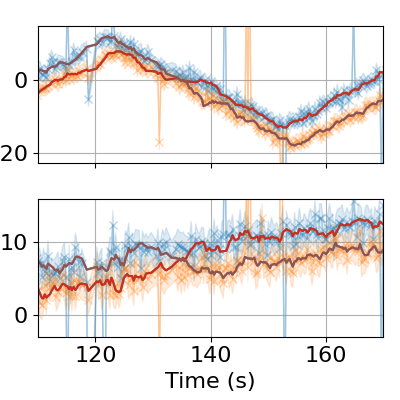

In [16]:
## JPDA with simulated detections
# plot the simulated measurements
coords = ['x', 'y'] # choose the coordinates to plot
fig_simPos_tracks = pu.plot_xyz_over_time(detections_df[0], label="simulated pos 0", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)
for i in range(1, len(detections_df)):
    pu.plot_xyz_over_time(detections_df[i], fig=fig_simPos_tracks, label=f"simulated pos {i}", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)

# plot the ground truth data
# for i, (topic, data) in enumerate(topic_data.items()):
#     if "GT" in topic:
#         pu.plot_xyz_over_time(data, fig=fig_simPos_tracks, label=f"Target {i+1}", linewidth=1.5, linestyle='--', coords=coords)

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(simPos_results_dfs):
    pu.plot_xyz_over_time(track_df, fig=fig_simPos_tracks, label=f"Track {i+1}", linewidth=1.5, coords=coords)
    # pu.plot_xyz_over_time(track_df, fig=fig_simPos_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i], coords=coords)

handles, labels = fig_simPos_tracks.axes[0].get_legend_handles_labels()
# fig_simPos_tracks.legend(handles, labels, loc='upper right')
# fig_simPos_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.97))
# fig_simPos_tracks.suptitle(f"white noise std {white_noise_std} m", fontsize=16, x=0.55)
fig_simPos_tracks.set_size_inches(4, 4)
# fig_simPos_tracks.tight_layout(rect=[0, 0, 0.775, 1.0])
# fig_simPos_tracks.subplots_adjust(top=0.91)  # Adjust top spacing
fig_simPos_tracks.align_ylabels()

# custom y-axis limits
fig_simPos_tracks.axes[0].set_ylim((-23, 15))
fig_simPos_tracks.axes[1].set_ylim((-3, 16))
# fig_simPos_tracks.axes[2].set_ylim((-7.5, 3))

# custom x-axis limits
for ax in fig_simPos_tracks.axes:
    ax.set_xlim((110, 170))
plt.show()

In [17]:
# fig_simPos_tracks.savefig(os.path.join(PLOTS_DIR, f"gating_2.0_wn1.0.svg"), dpi=600, bbox_inches='tight')

In [18]:
# pickle the results
# for i, detection in enumerate(detections_df):
#     detection.to_pickle(os.path.join(RESULTS_DIR, f"sl_gating_1.5_wn{white_noise_std}_detections_{i}.pkl"))
# for i, track_df in enumerate(simPos_results_dfs):
#     track_df.to_pickle(os.path.join(RESULTS_DIR, f"sl_gating_1.5_wn{white_noise_std}_tracks_{i}.pkl"))

In [19]:
# load the results
# import pandas as pd
# # Load the detections and tracks
# white_noise_std = 1.0
# detections_df = []
# for i in range(2):
#     detection = pd.read_pickle(os.path.join(RESULTS_DIR, f"wn{white_noise_std}_mh2.0_detections_{i}.pkl"))
#     detections_df.append(detection)
# simPos_results_dfs = []
# for i in range(100):
#     try:
#         track_df = pd.read_pickle(os.path.join(RESULTS_DIR, f"wn{white_noise_std}_mh2.0_tracks_{i}.pkl"))
#         simPos_results_dfs.append(track_df)
#     except FileNotFoundError as err:
#         print(err)
#         break  # Stop if no more tracks are available

#### Error analysis

In [20]:
# cut the data to the time range that is interesting
start_time = 110.0
end_time = 170.0
detections_df_cut = [df[(df['time'] >= start_time) & (df['time'] <= end_time)].reset_index(drop=True) for df in detections_df]
simPos_results_dfs = [df[(df['time'] >= start_time) & (df['time'] <= end_time)].reset_index(drop=True) for df in simPos_results_dfs]


# calculate the error for detections
err_det1 = dfu.calculate_position_error(
    topic_data["/machine_1/target_tracker/MTT/GT/target0"], 
    detections_df_cut[0], 
    abs=True
)
err_det2 = dfu.calculate_position_error(
    topic_data["/machine_1/target_tracker/MTT/GT/target2"], 
    detections_df_cut[1], 
    abs=True
)

err_stats_det1 = dfu.calculate_position_error_statistics(err_det1)
err_stats_det2 = dfu.calculate_position_error_statistics(err_det2)
logger.info(f"Error statistics for detection 1:\n{err_stats_det1}")
logger.info(f"Error statistics for detection 2:\n{err_stats_det2}")

# Calculate the error for selected tracks
# Tracks and targets need to be matched correctly
# err_track1 = dfu.calculate_position_error(
#     topic_data["/machine_1/target_tracker/MTT/GT/target0"], # target
#     simPos_results_dfs[0], # track
#     abs=True
# )
# err_track2 = dfu.calculate_position_error(
#     topic_data["/machine_1/target_tracker/MTT/GT/target2"], 
#     simPos_results_dfs[2], 
#     abs=True
# )
# err_track3 = dfu.calculate_position_error(
#     topic_data["/machine_1/target_tracker/MTT/GT/target2"],
#     simPos_results_dfs[4],  
#     abs=True
# )
# err_stats_track1 = dfu.calculate_position_error_statistics(err_track1)
# err_stats_track2 = dfu.calculate_position_error_statistics(err_track2)
# err_stats_track3 = dfu.calculate_position_error_statistics(err_track3)
# logger.info(f"Error statistics for track 1:\n{err_stats_track1}")
# logger.info(f"Error statistics for track 2:\n{err_stats_track2}")
# logger.info(f"Error statistics for track 3:\n{err_stats_track3}")

INFO: Calculating position errors...
INFO: Calculating position errors...
INFO: Error statistics for detection 1:
                       x          y         z      total
std             5.207594   4.460589  1.085593   6.774615
std_filtered    0.618233   0.698978  0.578141   0.702962
min             0.005220   0.007422  0.012630   0.251687
max            44.351567  39.590234  8.853932  51.120155
rms             5.469189   4.759152  1.423104   7.388286
mae             1.711311   1.688833  0.923367   2.986779
outlier_ratio   0.040000   0.040000  0.040000   0.040000
INFO: Error statistics for detection 2:
                       x          y         z      total
std             4.599630   3.361018  1.158714   5.699928
std_filtered    0.567817   0.734535  0.529554   0.714948
min             0.007822   0.001174  0.021392   0.104456
max            49.261036  35.885532  9.429045  57.228887
rms             4.784624   3.572323  1.463753   6.147901
mae             1.357132   1.233503  0.898148   

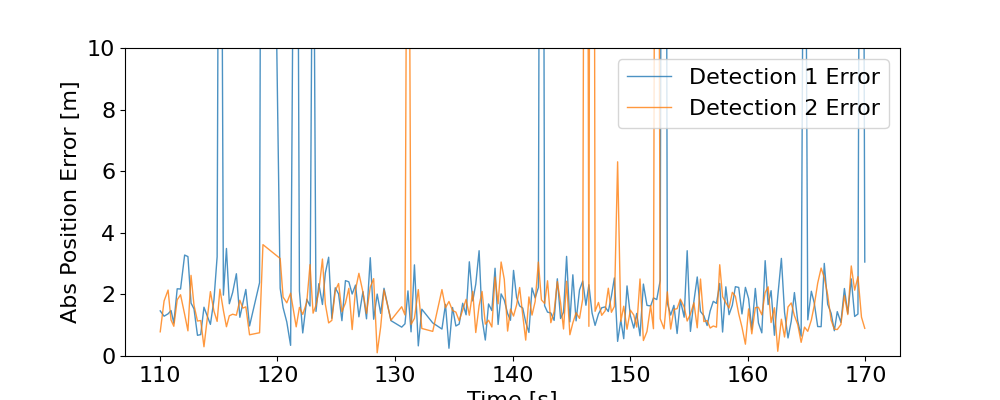

In [21]:
# Plot the errors
fig_errors = plt.figure(figsize=(10, 4))
plt.plot(err_det1['time'], err_det1['total'], label='Detection 1 Error', color='tab:blue',linewidth=1.0, alpha=0.8)
plt.plot(err_det2['time'], err_det2['total'], label='Detection 2 Error', color='tab:orange', linewidth=1.0, alpha=0.8)
# plt.plot(err_track1['time'], err_track1['total'], label='Track 1 Error', color='tab:brown', linewidth=1.5)
# plt.plot(err_track2['time'], err_track2['total'], label='Track 2 Error', color='tab:red', linewidth=1.5)
# plt.plot(err_track3['time'], err_track3['total'], label='Track 3 Error', color='tab:pink', linewidth=1.5)
plt.xlabel('Time [s]')
plt.ylabel('Abs Position Error [m]')
plt.legend()
plt.ylim(0, 10)
plt.show()

In [22]:
# fig_errors.savefig(os.path.join(PLOTS_DIR, f"noise_simpos_mn_gate1.5_wn{white_noise_std}_2zebra_errors.svg"), dpi=600, bbox_inches='tight')

### Tracking using ID measurements

#### Tracker using Simulated ID Detections

In [23]:
## TEST 3: JPDA Tracker using simulated id detections
id_gater = mtt.IDGater()
id_likelihood = mtt.IdLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=id_gater,
    likelihood=id_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
)

logger.info("Starting tracking using position detections")
# Evaluate the tracker using the grouped detections
for detection in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="Proj Position Tracking"):
    tracker.evaluate(detection)
id_results = tracker.tracks
print(f"Number of tracks: {len(id_results)}")

INFO: Starting tracking using position detections
Proj Position Tracking: 100%|██████████| 492/492 [00:00<00:00, 636.72it/s]

Number of tracks: 3


In [24]:
## Extract confirmed tracks
confirmed_id_tracks = [track for track in id_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_id_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in confirmed_id_tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
id_results_dfs = [dfu.track_to_dataframe(track) for track in confirmed_id_tracks]

Number of confirmed tracks: 2
Number of active tracks in the end: 2


#### Plots Simulated IDs

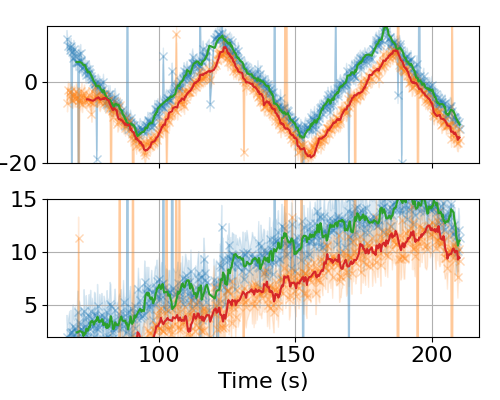

In [25]:
## JPDA with simulated detections
coords = ['x', 'y']
# plot the simulated measurements
fig_id_tracks = pu.plot_xyz_over_time(detections_df[0], label="simulated pos 0", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)
for i in range(1, len(detections_df)):
    pu.plot_xyz_over_time(detections_df[i], fig=fig_id_tracks, label=f"simulated pos {i}", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)

# plot the ground truth data
# for i, (topic, data) in enumerate(topic_data.items()):
#     if "GT" in topic:
#         pu.plot_xyz_over_time(data, fig=fig_id_tracks, label=f"Target {i+1}", linewidth=1.5, linestyle='--')

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(id_results_dfs):
    pu.plot_xyz_over_time(track_df, fig=fig_id_tracks, label=f"Track {i+1}", linewidth=1.5, coords=coords)
    # pu.plot_xyz_over_time(track_df, fig=fig_id_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i])

handles, labels = fig_id_tracks.axes[0].get_legend_handles_labels()
# fig_id_tracks.legend(handles, labels, loc='upper right')
# fig_id_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.926))
fig_id_tracks.suptitle("")
fig_id_tracks.set_size_inches(5, 4)
# fig_id_tracks.tight_layout(rect=[0, 0, 0.76, 1.0])
fig_id_tracks.align_ylabels()

# custom y-axis limits
fig_id_tracks.axes[0].set_ylim((-20, 14))
fig_id_tracks.axes[1].set_ylim((2, 15))
# fig_id_tracks.axes[2].set_ylim((-7.5, 1))

# custom x-axis limits
# for ax in fig_id_tracks.axes:
#     ax.set_xlim((100, 160))
plt.show()

In [26]:
# fig_id_tracks.savefig(os.path.join(PLOTS_DIR, f"simulated_id_mn_gate0.1_mean{id_mean}_std{id_std}_outlier{id_outlier}_2zebra.svg"), dpi=600, bbox_inches='tight')

In [27]:
# probabilities = []
# for i, detection in enumerate(detections):
#     logger.info(f"Processing detection {i}")
#     probabilities.append(np.array([meas.id for meas in detection]))
# print(zebra_ids)

# # plot the probabilities over time
# fig_prob = plt.figure()
# for i, (time, prob, zebra_idx) in enumerate(zip(timestamps, probabilities, zebra_ids)):
#     plt.plot(time, prob[:, zebra_idx], label=f"Zebra {i}", linewidth=1.0)
# # plt.title("Zebra Identification Probabilities")
# plt.xlabel("Time [s]")
# plt.ylabel("Probability")
# plt.legend()
# plt.show()

# # plot the probabilities over time
# fig_prob = plt.figure()
# for i in range(10):
#     plt.plot(timestamps[0], probabilities[0][:, i], label=f"Zebra {i}", linewidth=1.0)
# # plt.title("Zebra Identification Probabilities")
# plt.xlabel("Time [s]")
# plt.ylabel("Probability")
# plt.legend()
# plt.show()
# # plt.savefig(os.path.join(PLOTS_DIR, "zebra_identification_probabilities_gt.svg"), dpi=600, bbox_inches='tight')

## Dataset with 6 zebras

### Configuration and Data Extraction

In [28]:
# since data is generated based on GT use a file with 6 zebras
BAG_PATH = os.path.join(project_root, 'data/6_zebras_3_drones_gps_drift.bag')

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
# rbu.display_rosbag_info(bag_reader)

topics = [
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/target_tracker/MTT/GT/target1",
    "/machine_1/target_tracker/MTT/GT/target2",
    "/machine_1/target_tracker/MTT/GT/target3",
    "/machine_1/target_tracker/MTT/GT/target4",
    "/machine_1/target_tracker/MTT/GT/target5",
    "/machine_1/object_detections/projected_to_world",
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target1' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target2' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target3' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target4' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target5' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


In [29]:
projected_array = rbu.import_detections_array_data(bag_reader, "/machine_1/object_detections/projected_to_world_array")
# Convert to DataFrame
time = []
meas = []
for timestamp, measurements, drone_id in projected_array:
    for measurement in measurements:
        time.append(timestamp)
        meas.append(measurement)
time = np.array(time)
meas = np.array(meas)
# Create DataFrame
projected_array_df = dfu.measurements_to_dataframe(meas, time)

INFO: Importing detections array data from topics: /machine_1/object_detections/projected_to_world_array


### Simulate Detections

In [30]:
# match the frequency of the simulated detections
projected_array_reduced_df = dfu.clean_duplicate_timestamps(projected_array_df)
print(f"Number of projected detections after cleaning: {len(projected_array_reduced_df)}")

detections = []
for topic, data in topic_data.items():
    if "GT" in topic:
        logger.info(f"Reindexing GT data from topic {topic} to match projected detections")
        reindexed_data = dfu.reindex_dataframe(data, projected_array_reduced_df)
        detections.append(reindexed_data)

# simulate position detections
timestamps = []
white_noise_std = 0.5
for idx, detection in enumerate(detections):
    t, detections[idx] = ss.simulate_position_sensor(
        detection,
        white_noise_std=[white_noise_std]*3,  # white noise
        # random_walk=True,  # Enable random walk
        # bounds=[3, 3, 1],  # Bounds for the random walk
        outlier_percentage=0.04,  # outlier percentage
        outlier_std=[50, 50, 10]  # Outlier standard deviation
    )
    timestamps.append(t)

# create simulated zebra database
zebra_db, zebra_ids = ss.create_zebra_db(
    zebras_in_db=20, 
    zebras_in_gt=6, 
)
# simulate zebra identification
id_mean = 0.3
id_std = 0.2
id_outlier = 0.
detections = ss.simulate_zebra_identification(
    zebra_trajectories=detections,
    zebra_ids_db=zebra_db,
    zebra_ids_meas=zebra_ids,
    mean_confidence=id_mean,
    confidence_std=id_std,
    outlier_percentage=id_outlier,
)

# Convert detections to DataFrame for visualization
detections_df = []
for timestamp, detection in zip(timestamps, detections):
    detections_df.append(dfu.measurements_to_dataframe(detection, timestamp))

# Combine detections for both targets
gt_detections = np.concatenate(detections)
gt_time = np.concatenate(timestamps)

# group the detections by time using numpy
groups = np.zeros(gt_detections.shape, dtype=float)
for idx, (time, meas) in enumerate(zip(gt_time, gt_detections)):
    groups[idx] = round(time * 100) / 100

# sort both arrays by time
gt_detections = gt_detections[np.argsort(groups)]
groups = groups[np.argsort(groups)]

# group the detections by time using numpy
gt_grouped_detections = np.split(gt_detections, np.unique(groups, return_index=True)[1][1:])
# get the corresponding time values for each group
gt_grouped_time = np.unique(groups)

id_gdata = []
data_drone_id = [1 for _ in range(len(gt_grouped_detections))] # ID of the drone is 1 because it is from machine 1
# check if a row has only one measurement
for i, group in enumerate(zip(gt_grouped_time, gt_grouped_detections, data_drone_id)):
    id_gdata.append(group)
    if len(group[1]) == 1:
        print(f"Frame {i} has only one measurement: {group[0]}")

# Log info about the grouped measurements
logger.info(f"Grouped {len(gt_detections)} GT measurements into {len(gt_grouped_detections)} frames")
logger.info(f"Average measurements per frame: {len(gt_detections) / len(gt_grouped_detections):.2f}")

INFO: Reindexing GT data from topic /machine_1/target_tracker/MTT/GT/target0 to match projected detections
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [60.092, 246.936]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.
INFO: Reindexing GT data from topic /machine_1/target_tracker/MTT/GT/target1 to match projected detections
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [60.092, 246.936]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.
INFO: Reindexing GT data from topic /machine_1/target_tracker/MTT/GT/target2 to match projected detections
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [60.092, 246.936]
INFO: Interpolating source_df t

Number of projected detections after cleaning: 402


INFO: Grouped 2412 GT measurements into 402 frames
INFO: Average measurements per frame: 6.00


### Track Simulated Position Detections

#### Tracker

In [31]:
## TEST 2: JPDA Tracker using simulated position detections
gater = mtt.MahalanobisGater()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=score_logic,
    drone_id=None, # offset estimation for single drone tracking
)

logger.info("Starting tracking using position detections")
# Evaluate the tracker using the grouped detections
for detection in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="Proj Position Tracking"):
    tracker.evaluate(detection)
simPos_results = tracker.tracks
print(f"Number of tracks: {len(simPos_results)}")

INFO: Starting tracking using position detections
Proj Position Tracking: 100%|██████████| 402/402 [00:07<00:00, 53.04it/s]

Number of tracks: 15


In [32]:
## Extract confirmed tracks
confirmed_simPos_tracks = [track for track in simPos_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_simPos_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_simPos_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in confirmed_simPos_tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
simPos_results_dfs = [dfu.track_to_dataframe(track) for track in confirmed_simPos_tracks]

Number of confirmed tracks: 12
Number of active tracks in the end: 12


#### Plots

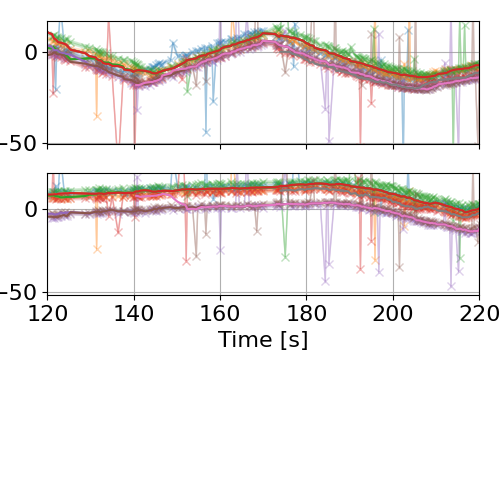

In [33]:
## JPDA with simulated detections
# plot the simulated measurements
fig_simPos_tracks = pu.plot_xyz_over_time(detections_df[0], label="simulated pos 0", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True)
for i in range(1, len(detections_df)):
    pu.plot_xyz_over_time(detections_df[i], fig=fig_simPos_tracks, label=f"simulated pos {i}", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True)

# plot the ground truth data
# for i, (topic, data) in enumerate(topic_data.items()):
#     if "GT" in topic:
#         pu.plot_xyz_over_time(data, fig=fig_simPos_tracks, label=f"Target {i+1}", linewidth=1.5, linestyle='--')

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(simPos_results_dfs):
    pu.plot_xyz_over_time(track_df, fig=fig_simPos_tracks, label=f"Track {i+1}", linewidth=1.5)
    # pu.plot_xyz_over_time(track_df, fig=fig_simPos_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i])

handles, labels = fig_simPos_tracks.axes[0].get_legend_handles_labels()
# fig_simPos_tracks.legend(handles, labels, loc='upper right')
# fig_simPos_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.926))
fig_simPos_tracks.suptitle("")
fig_simPos_tracks.set_size_inches(5, 5)
# fig_simPos_tracks.tight_layout(rect=[0, 0, 0.76, 1.0])
fig_simPos_tracks.align_ylabels()

# custom y-axis limits
# fig_simPos_tracks.axes[0].set_ylim((-20, 14))
# fig_simPos_tracks.axes[1].set_ylim((2, 15))
# fig_simPos_tracks.axes[2].set_ylim((-7.5, 1))

# custom x-axis limits
for ax in fig_simPos_tracks.axes:
    ax.set_xlim((120, 220))

# Remove the third subplot (z axis)
# Make sure x-axis labels are shown on the second subplot before removing the third
fig_simPos_tracks.axes[1].xaxis.set_tick_params(labelbottom=True)
fig_simPos_tracks.axes[1].set_xlabel('Time [s]')
fig_simPos_tracks.delaxes(fig_simPos_tracks.axes[2])  # Remove the 3rd subplot (z-axis)
plt.show()

In [34]:
# fig_simPos_tracks.savefig(os.path.join(PLOTS_DIR, f"simpos_sl_wn{white_noise_std}_gate1.3_6zebra.svg"), dpi=600, bbox_inches='tight')

In [35]:
# pickle the results
# for i, detection in enumerate(detections_df):
#     detection.to_pickle(os.path.join(RESULTS_DIR, f"simpos_sl_wn{white_noise_std}_gate1.3_detections_{i}.pkl"))
# for i, track_df in enumerate(simPos_results_dfs):
#     track_df.to_pickle(os.path.join(RESULTS_DIR, f"simpos_sl_wn{white_noise_std}_gate1.3_tracks_{i}.pkl"))

In [36]:
# load the results
# import pandas as pd
# # Load the detections and tracks
# white_noise_std = 0.5
# detections_df = []
# for i in range(100):
#     try:
#         detection = pd.read_pickle(os.path.join(RESULTS_DIR, '6_zebras', f"simpos_sl_wn{white_noise_std}_gate1.4_detections_{i}.pkl"))
#         detections_df.append(detection)
#     except FileNotFoundError:
#         break  # Stop if no more tracks are available
# simPos_results_dfs = []
# for i in range(100):
#     try:
#         track_df = pd.read_pickle(os.path.join(RESULTS_DIR, '6_zebras', f"simpos_sl_wn{white_noise_std}_gate1.4_tracks_{i}.pkl"))
#         simPos_results_dfs.append(track_df)
#     except FileNotFoundError:
#         break  # Stop if no more tracks are available

### Track ID Detections

#### Tracker

In [37]:
## TEST 3: JPDA Tracker using simulated id detections
id_gater = mtt.IDGater()
id_likelihood = mtt.IdLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=id_gater,
    likelihood=id_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
)

logger.info("Starting tracking using position detections")
# Evaluate the tracker using the grouped detections
for detection in tqdm.tqdm(id_gdata, total=len(id_gdata), desc="Proj Position Tracking"):
    tracker.evaluate(detection)
id_results = tracker.tracks
print(f"Number of tracks: {len(id_results)}")

INFO: Starting tracking using position detections
Proj Position Tracking: 100%|██████████| 402/402 [00:05<00:00, 76.15it/s] 

Number of tracks: 26


In [38]:
## Extract confirmed tracks
confirmed_id_tracks = [track for track in id_results if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_id_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in confirmed_id_tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
simPos_results_dfs = [dfu.track_to_dataframe(track) for track in confirmed_id_tracks]

Number of confirmed tracks: 6
Number of active tracks in the end: 6


#### Plots

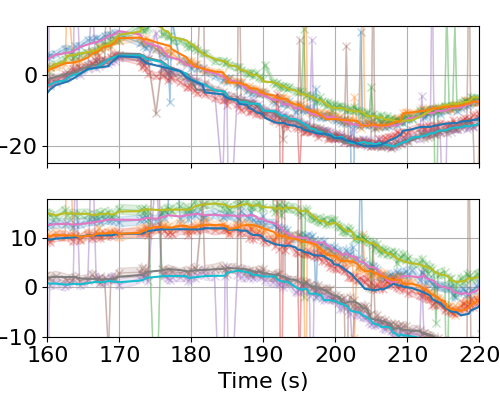

In [39]:
## JPDA with simulated detections
# plot the simulated measurements
coords = ['x', 'y'] # choose the coordinates to plot
fig_id_tracks = pu.plot_xyz_over_time(detections_df[0], label="simulated pos 0", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)
for i in range(1, len(detections_df)):
    pu.plot_xyz_over_time(detections_df[i], fig=fig_id_tracks, label=f"simulated pos {i}", alpha=0.3, marker='x', show_uncertainty=True, noisy_limits=True, coords=coords)

# plot the ground truth data
# for i, (topic, data) in enumerate(topic_data.items()):
#     if "GT" in topic:
#         pu.plot_xyz_over_time(data, fig=fig_id_tracks, label=f"Target {i+1}", linewidth=1.5, linestyle='--', coords=coords)

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(simPos_results_dfs):
    pu.plot_xyz_over_time(track_df, fig=fig_id_tracks, label=f"Track {i+1}", linewidth=1.5, coords=coords)
    # pu.plot_xyz_over_time(track_df, fig=fig_id_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i], coords=coords)

handles, labels = fig_id_tracks.axes[0].get_legend_handles_labels()
# fig_id_tracks.legend(handles, labels, loc='upper right')
# fig_id_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.926))
fig_id_tracks.suptitle("")
fig_id_tracks.set_size_inches(5, 4)
# fig_id_tracks.tight_layout(rect=[0, 0, 0.76, 1.0])
fig_id_tracks.align_ylabels()

# custom y-axis limits
fig_id_tracks.axes[0].set_ylim((-25, 14))
fig_id_tracks.axes[1].set_ylim((-10, 18))
# fig_id_tracks.axes[2].set_ylim((-4, 1))

# custom x-axis limits
for ax in fig_id_tracks.axes:
    ax.set_xlim((160, 220))

plt.show()

In [40]:
# fig_id_tracks.savefig(os.path.join(PLOTS_DIR, f"simulated_id_mn_gate0.1_mean{id_mean}_std{id_std}_outlier{id_outlier}_6zebra.svg"), dpi=600, bbox_inches='tight')